**Skin Cancer Classification using EfficientNetV2** This notebook implements a modular deep learning solution for classifying skin lesions across 7 different categories using the HAM10000 dataset. We use EfficientNetV2 architecture with PyTorch and implement data augmentation techniques to handle class imbalance.

##**1. Environment Setup and Imports**
First, we'll set up the environment by importing necessary libraries and setting random seeds for reproducibility.

In [3]:
# Standard Python libraries
import os
import time
import copy
import random
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from glob import glob
from PIL import Image
from tqdm import tqdm

# PyTorch libraries
import torch
from torch import optim, nn
from torch.optim import lr_scheduler
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
import torch.nn.functional as F
import timm  # For accessing EfficientNetV2 models

# Scikit-learn libraries
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split, StratifiedKFold

# Set random seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

# Check GPU availability
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda:0


##**2. Configuration Parameters**
Let's define all the configuration parameters in a single class for better organization.

In [4]:

# THIS IS FOR THE EFFICIENT_V2 LARGE VARIANT
class Config:
    # Dataset parameters
    DATA_DIR = '/content/skin-cancer-mnist-ham10000'
    NORM_MEAN = [0.485, 0.456, 0.406]  # ImageNet normalization values
    NORM_STD = [0.229, 0.224, 0.225]   # ImageNet normalization values
    IMG_SIZE = 480  # EfficientNetV2-L optimal input size

    # Model parameters
    NUM_CLASSES = 7
    MODEL_NAME = 'tf_efficientnetv2_l_in21ft1k'  # Large variant
    PRETRAINED = True
    FEATURE_EXTRACT = False
    DROPOUT_RATE = 0.3

    # Training parameters
    BATCH_SIZE = 8  # Reduced batch size
    NUM_WORKERS = 4
    NUM_EPOCHS = 20
    LEARNING_RATE = 4e-4  # Slightly reduced learning rate
    WEIGHT_DECAY = 1e-5
    USE_AMP = True
    GRAD_ACCUMULATION = 4  # Increased gradient accumulation
    EARLY_STOPPING_PATIENCE = 5

    # Paths for saving models and logs
    OUTPUT_DIR = './output'
    CHECKPOINT_DIR = os.path.join(OUTPUT_DIR, 'checkpoints')
    LOG_DIR = os.path.join(OUTPUT_DIR, 'logs')

    # Class mapping
    LESION_TYPE_DICT = {
        'nv': 'Melanocytic nevi',
        'mel': 'Melanoma',
        'bkl': 'Benign keratosis-like lesions',
        'bcc': 'Basal cell carcinoma',
        'akiec': 'Actinic keratoses',
        'vasc': 'Vascular lesions',
        'df': 'Dermatofibroma'
    }

    # Device configuration
    DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
    RANDOM_SEED = 42

# Create the config object
config = Config()

# Create output directories
os.makedirs(config.OUTPUT_DIR, exist_ok=True)
os.makedirs(config.CHECKPOINT_DIR, exist_ok=True)
os.makedirs(config.LOG_DIR, exist_ok=True)

In [2]:
# THIS IS FOR THE EFFICIENT_V2 SMALL VARIANT
# class Config:
#     # Dataset parameters
#     DATA_DIR = '/content/skin-cancer-mnist-ham10000'
#     NORM_MEAN = [0.485, 0.456, 0.406]  # ImageNet normalization values
#     NORM_STD = [0.229, 0.224, 0.225]   # ImageNet normalization values
#     IMG_SIZE = 384  # EfficientNetV2-S optimal input size

#     # Model parameters
#     NUM_CLASSES = 7
#     MODEL_NAME = 'efficientnetv2_s'  # Using the small variant
#     PRETRAINED = True
#     FEATURE_EXTRACT = False  # False for fine-tuning, True for feature extraction
#     DROPOUT_RATE = 0.3

#     # Training parameters
#     BATCH_SIZE = 16
#     NUM_WORKERS = 4
#     NUM_EPOCHS = 20
#     LEARNING_RATE = 5e-4
#     WEIGHT_DECAY = 1e-5
#     USE_AMP = True  # Use Automatic Mixed Precision for faster training
#     GRAD_ACCUMULATION = 2  # Gradient accumulation steps for effective larger batch size
#     EARLY_STOPPING_PATIENCE = 5

#     # Paths for saving models and logs
#     OUTPUT_DIR = './output'
#     CHECKPOINT_DIR = os.path.join(OUTPUT_DIR, 'checkpoints')
#     LOG_DIR = os.path.join(OUTPUT_DIR, 'logs')

#     # Class mapping
#     LESION_TYPE_DICT = {
#         'nv': 'Melanocytic nevi',
#         'mel': 'Melanoma',
#         'bkl': 'Benign keratosis-like lesions',
#         'bcc': 'Basal cell carcinoma',
#         'akiec': 'Actinic keratoses',
#         'vasc': 'Vascular lesions',
#         'df': 'Dermatofibroma'
#     }

#     # Device configuration
#     DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
#     RANDOM_SEED = 42

# # Create the config object
# config = Config()

# # Create output directories
# os.makedirs(config.OUTPUT_DIR, exist_ok=True)
# os.makedirs(config.CHECKPOINT_DIR, exist_ok=True)
# os.makedirs(config.LOG_DIR, exist_ok=True)

##**Let's download and extract the dataset**

In [3]:
# This cell would work on Google Colab
# Install required packages
!pip install -q kaggle timm==0.9.5 torch torchvision

# Mount Google Drive (if using Colab)
from google.colab import drive
drive.mount('/content/drive')

# Configure Kaggle API credentials
!mkdir -p ~/.kaggle
!cp "/content/drive/MyDrive/Colab Notebooks/kaggle_api_key/kaggle.json" ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Download the HAM10000 skin cancer dataset
!kaggle datasets download -d kmader/skin-cancer-mnist-ham10000
!unzip /content/skin-cancer-mnist-ham10000.zip -d /content/skin-cancer-mnist-ham10000

Streaming output truncated to the last 5000 lines.
  inflating: /content/skin-cancer-mnist-ham10000/ham10000_images_part_2/ISIC_0029325.jpg  
  inflating: /content/skin-cancer-mnist-ham10000/ham10000_images_part_2/ISIC_0029326.jpg  
  inflating: /content/skin-cancer-mnist-ham10000/ham10000_images_part_2/ISIC_0029327.jpg  
  inflating: /content/skin-cancer-mnist-ham10000/ham10000_images_part_2/ISIC_0029328.jpg  
  inflating: /content/skin-cancer-mnist-ham10000/ham10000_images_part_2/ISIC_0029329.jpg  
  inflating: /content/skin-cancer-mnist-ham10000/ham10000_images_part_2/ISIC_0029330.jpg  
  inflating: /content/skin-cancer-mnist-ham10000/ham10000_images_part_2/ISIC_0029331.jpg  
  inflating: /content/skin-cancer-mnist-ham10000/ham10000_images_part_2/ISIC_0029332.jpg  
  inflating: /content/skin-cancer-mnist-ham10000/ham10000_images_part_2/ISIC_0029333.jpg  
  inflating: /content/skin-cancer-mnist-ham10000/ham10000_images_part_2/ISIC_0029334.jpg  
  inflating: /content/skin-cancer-mnist

##**3. Data Preparation and Loading**
Let's define our custom dataset class and all data loading functions with enhanced augmentation.

In [5]:
class HAM10000Dataset(Dataset):
    """Custom PyTorch Dataset for HAM10000 skin lesion images."""
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        img_path = self.dataframe['path'][index]
        image = Image.open(img_path).convert('RGB')  # Ensure RGB format
        label = torch.tensor(int(self.dataframe['cell_type_idx'][index]))

        if self.transform:
            image = self.transform(image)

        return image, label

class Mixup:
    """Mixup augmentation for image classification."""
    def __init__(self, alpha=0.2):
        self.alpha = alpha

    def __call__(self, batch):
        """
        Args:
            batch: Mini-batch of (images, labels)
        Returns:
            Mixed inputs, pairs of targets, and lambda value
        """
        images, labels = batch
        batch_size = images.size(0)

        # Sample lambda from beta distribution
        if self.alpha > 0:
            lam = np.random.beta(self.alpha, self.alpha)
        else:
            lam = 1

        # Create shuffled indices
        index = torch.randperm(batch_size).to(images.device)

        # Mix images
        mixed_images = lam * images + (1 - lam) * images[index, :]

        # Return mixed images and labels
        return mixed_images, labels, labels[index], lam

class DataModule:
    def __init__(self, config):
        self.config = config

        # Define augmentations
        self.train_transform = transforms.Compose([
            transforms.Resize((config.IMG_SIZE, config.IMG_SIZE)),
            transforms.RandomHorizontalFlip(),
            transforms.RandomVerticalFlip(),
            transforms.RandomRotation(20),
            transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
            # Advanced augmentations for medical imaging
            transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
            transforms.RandomResizedCrop(config.IMG_SIZE, scale=(0.8, 1.0)),
            transforms.ToTensor(),
            transforms.Normalize(config.NORM_MEAN, config.NORM_STD)
        ])

        self.val_transform = transforms.Compose([
            transforms.Resize((config.IMG_SIZE, config.IMG_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize(config.NORM_MEAN, config.NORM_STD)
        ])

        self.test_transform = self.val_transform

        # Initialize mixup augmentation
        self.mixup = Mixup(alpha=0.2)

    def prepare_data(self):
        # Create image path mapping
        all_image_paths = glob(os.path.join(self.config.DATA_DIR, '*', '*.jpg'))
        self.image_id_to_path_dict = {os.path.splitext(os.path.basename(x))[0]: x for x in all_image_paths}

        # Load metadata
        self.df_metadata = pd.read_csv(os.path.join(self.config.DATA_DIR, 'HAM10000_metadata.csv'))

        # Add image path and class information
        self.df_metadata['path'] = self.df_metadata['image_id'].map(self.image_id_to_path_dict.get)
        self.df_metadata['cell_type'] = self.df_metadata['dx'].map(self.config.LESION_TYPE_DICT.get)
        self.df_metadata['cell_type_idx'] = pd.Categorical(self.df_metadata['cell_type']).codes

        # Handle duplicated images to prevent data leakage
        self._handle_duplicates()

        # Create train/val/test splits
        self._create_splits()

        # Balance classes in training set
        self._balance_classes()

    def _handle_duplicates(self):
        # Find lesions with only one image
        df_lesion_counts = self.df_metadata.groupby('lesion_id').count()
        df_unique_lesions = df_lesion_counts[df_lesion_counts['image_id'] == 1]
        df_unique_lesions.reset_index(inplace=True)

        # Function to determine if a lesion has duplicate images
        def identify_duplicates(lesion_id):
            unique_lesion_ids = list(df_unique_lesions['lesion_id'])
            return 'unduplicated' if lesion_id in unique_lesion_ids else 'duplicated'

        # Add a column indicating if the image is a duplicate
        self.df_metadata['duplicates'] = self.df_metadata['lesion_id'].apply(identify_duplicates)

    def _create_splits(self):
        # Filter out images without duplicates for validation set creation
        df_unique = self.df_metadata[self.df_metadata['duplicates'] == 'unduplicated']

        # Create a validation set (20% of unique images)
        y_unique = df_unique['cell_type_idx']
        _, self.df_val = train_test_split(df_unique, test_size=0.2,
                                          random_state=self.config.RANDOM_SEED, stratify=y_unique)

        # Function to determine if an image is in validation set
        def identify_dataset_split(image_id):
            val_image_ids = list(self.df_val['image_id'])
            return 'val' if str(image_id) in val_image_ids else 'train'

        # Mark each image as train or validation
        self.df_metadata['train_or_val'] = self.df_metadata['image_id'].apply(identify_dataset_split)

        # Create training dataframe
        self.df_train = self.df_metadata[self.df_metadata['train_or_val'] == 'train']

        # Split validation set into validation and test sets
        self.df_val, self.df_test = train_test_split(self.df_val, test_size=0.5,
                                                     random_state=self.config.RANDOM_SEED)

        # Reset indices
        self.df_train = self.df_train.reset_index(drop=True)
        self.df_val = self.df_val.reset_index(drop=True)
        self.df_test = self.df_test.reset_index(drop=True)

    def _balance_classes(self):
        # Calculate class distributions
        class_counts = self.df_train['cell_type_idx'].value_counts().sort_index()
        max_count = class_counts.max()

        # Calculate oversampling rates to approach balanced distribution
        oversampling_rates = {}
        for class_idx, count in class_counts.items():
            # Calculate how many times to oversample (at least 1)
            rate = max(1, int(max_count / count))
            oversampling_rates[class_idx] = rate

        # Apply oversampling
        balanced_dfs = [self.df_train]
        for class_idx, rate in oversampling_rates.items():
            if rate > 1:
                # Get samples for this class
                class_samples = self.df_train[self.df_train['cell_type_idx'] == class_idx].copy()
                # Add copies (rate-1 times)
                for _ in range(rate - 1):
                    balanced_dfs.append(class_samples)

        # Combine oversampled data
        self.df_train = pd.concat(balanced_dfs, ignore_index=True)

    def create_dataloaders(self):
        # Create training dataset and loader
        training_set = HAM10000Dataset(self.df_train, transform=self.train_transform)
        train_loader = DataLoader(
            training_set,
            batch_size=self.config.BATCH_SIZE,
            shuffle=True,
            num_workers=self.config.NUM_WORKERS,
            pin_memory=True
        )

        # Create validation dataset and loader
        validation_set = HAM10000Dataset(self.df_val, transform=self.val_transform)
        val_loader = DataLoader(
            validation_set,
            batch_size=self.config.BATCH_SIZE,
            shuffle=False,
            num_workers=self.config.NUM_WORKERS,
            pin_memory=True
        )

        # Create test dataset and loader
        test_set = HAM10000Dataset(self.df_test, transform=self.test_transform)
        test_loader = DataLoader(
            test_set,
            batch_size=self.config.BATCH_SIZE,
            shuffle=False,
            num_workers=self.config.NUM_WORKERS,
            pin_memory=True
        )

        return train_loader, val_loader, test_loader

    def get_class_names(self):
        # Get ordered class names for evaluation
        return [self.config.LESION_TYPE_DICT[dx] for dx in
                self.df_metadata['dx'].unique().tolist()]

**Let's execute our data preparation code:**

In [6]:
# Initialize data module
data_module = DataModule(config)
data_module.prepare_data()
train_loader, val_loader, test_loader = data_module.create_dataloaders()
class_names = data_module.get_class_names()

# Print dataset information
print(f"Training set size: {len(data_module.df_train)}")
print(f"Validation set size: {len(data_module.df_val)}")
print(f"Test set size: {len(data_module.df_test)}")

# Display class distribution in training set
train_class_dist = data_module.df_train['cell_type'].value_counts()
print("\nTraining set class distribution after balancing:")
print(train_class_dist)

Training set size: 39186
Validation set size: 551
Test set size: 552

Training set class distribution after balancing:
cell_type
Melanocytic nevi                 5822
Vascular lesions                 5805
Dermatofibroma                   5778
Basal cell carcinoma             5748
Actinic keratoses                5643
Melanoma                         5335
Benign keratosis-like lesions    5055
Name: count, dtype: int64


##**4. Model Architecture**
Let's define our EfficientNetV2 model architecture:

In [7]:
class ModelModule:
    def __init__(self, config):
        self.config = config

    def initialize_model(self):
        """Initialize and configure the EfficientNetV2 model architecture."""
        # Load pretrained EfficientNetV2 model using timm
        try:
            model = timm.create_model(
                self.config.MODEL_NAME,
                pretrained=self.config.PRETRAINED,
                num_classes=self.config.NUM_CLASSES,
                drop_rate=self.config.DROPOUT_RATE
            )
            print(f"Successfully loaded pretrained {self.config.MODEL_NAME}")
        except RuntimeError as e:
            print(f"Could not load pretrained weights for {self.config.MODEL_NAME}. Using random initialization.")
            # Fall back to random initialization
            model = timm.create_model(
                self.config.MODEL_NAME,
                pretrained=False,
                num_classes=self.config.NUM_CLASSES,
                drop_rate=self.config.DROPOUT_RATE
            )

        # Set feature extraction or fine-tuning
        if self.config.FEATURE_EXTRACT:
            # Freeze all parameters except the classifier
            for param in model.parameters():
                param.requires_grad = False

            # Unfreeze the classifier
            for param in model.head.parameters():
                param.requires_grad = True

        # Move model to device
        model = model.to(self.config.DEVICE)

        return model

# Initialize model
model_module = ModelModule(config)
model = model_module.initialize_model()

# Print model summary
print(f"Model: {config.MODEL_NAME}")
print(f"Feature extraction mode: {config.FEATURE_EXTRACT}")

/usr/local/lib/python3.11/dist-packages/timm/models/_factory.py:114: UserWarning: Mapping deprecated model name tf_efficientnetv2_l_in21ft1k to current tf_efficientnetv2_l.in21k_ft_in1k.
  model = create_fn(
/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Successfully loaded pretrained tf_efficientnetv2_l_in21ft1k
Model: tf_efficientnetv2_l_in21ft1k
Feature extraction mode: False


##**5. Training Setup**
Let's define our training and validation functions with improved features:

In [8]:
class MetricTracker:
    """Utility class for tracking metrics during training/validation."""
    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0

    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count

class EarlyStopping:
    """Early stopping to prevent overfitting"""
    def __init__(self, patience=5, min_delta=0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = float('inf')
        self.early_stop = False

    def __call__(self, val_loss):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        return self.early_stop

class TrainModule:
    def __init__(self, config, model, train_loader, val_loader):
        self.config = config
        self.model = model
        self.train_loader = train_loader
        self.val_loader = val_loader

        # Initialize optimizer
        self.optimizer = optim.AdamW(
            model.parameters(),
            lr=config.LEARNING_RATE,
            weight_decay=config.WEIGHT_DECAY
        )

        # Loss function with label smoothing for better generalization
        self.criterion = nn.CrossEntropyLoss(label_smoothing=0.1).to(config.DEVICE)

        # Learning rate scheduler - cosine annealing with warmup
        self.scheduler = torch.optim.lr_scheduler.OneCycleLR(
            self.optimizer,
            max_lr=config.LEARNING_RATE,
            total_steps=len(train_loader) * config.NUM_EPOCHS // config.GRAD_ACCUMULATION,
            pct_start=0.1,  # Warmup for 10% of training
            div_factor=10,
            final_div_factor=1000
        )

        # Early stopping
        self.early_stopping = EarlyStopping(patience=config.EARLY_STOPPING_PATIENCE)

        # Gradient scaler for mixed precision training
        self.scaler = torch.cuda.amp.GradScaler(enabled=config.USE_AMP)

        # Lists to store metrics
        self.train_losses = []
        self.train_accs = []
        self.val_losses = []
        self.val_accs = []

        # Best model tracking
        self.best_model_wts = copy.deepcopy(model.state_dict())
        self.best_val_acc = 0.0

        # Initialize GradCAM for visualization
        self.activation = {}

    def _mixup_criterion(self, pred, y_a, y_b, lam):
        """Mixup loss function"""
        return lam * self.criterion(pred, y_a) + (1 - lam) * self.criterion(pred, y_b)

    def train_one_epoch(self, epoch):
        """Train the model for one epoch"""
        # Set model to training mode
        self.model.train()

        # Initialize metric trackers
        train_loss = MetricTracker()
        train_acc = MetricTracker()

        # For logging progress
        pbar = tqdm(enumerate(self.train_loader), total=len(self.train_loader), desc=f"Epoch {epoch}/{self.config.NUM_EPOCHS}")

        # Iterate through batches
        for i, (images, labels) in pbar:
            # Get batch size
            batch_size = images.size(0)

            # Move data to device
            images = images.to(self.config.DEVICE)
            labels = labels.to(self.config.DEVICE)

            # Apply mixup augmentation with 50% probability
            if random.random() > 0.5:
                images, labels_a, labels_b, lam = data_module.mixup((images, labels))
                mixup_used = True
            else:
                mixup_used = False

            # Use automatic mixed precision for faster training
            with torch.cuda.amp.autocast(enabled=self.config.USE_AMP):
                # Forward pass
                outputs = self.model(images)

                # Calculate loss
                if mixup_used:
                    loss = self._mixup_criterion(outputs, labels_a, labels_b, lam)
                else:
                    loss = self.criterion(outputs, labels)

            # Scale the loss for gradient accumulation
            loss = loss / self.config.GRAD_ACCUMULATION

            # Backward pass with gradient scaling
            self.scaler.scale(loss).backward()

            # Gradient accumulation
            if (i + 1) % self.config.GRAD_ACCUMULATION == 0 or (i + 1) == len(self.train_loader):
                # Gradient clipping to prevent exploding gradients
                self.scaler.unscale_(self.optimizer)
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)

                # Optimizer step with gradient scaling
                self.scaler.step(self.optimizer)
                self.scaler.update()
                self.optimizer.zero_grad()

                # Update scheduler
                self.scheduler.step()

            # Calculate accuracy (only if not using mixup)
            if not mixup_used:
                _, predictions = torch.max(outputs, 1)
                correct = (predictions == labels).sum().item()
                accuracy = correct / batch_size
                train_acc.update(accuracy)

            # Update loss metric
            train_loss.update(loss.item() * self.config.GRAD_ACCUMULATION)

            # Update progress bar
            pbar.set_postfix({
                'Loss': f"{train_loss.avg:.5f}",
                'Acc': f"{train_acc.avg:.5f}",
                'LR': f"{self.optimizer.param_groups[0]['lr']:.6f}"
            })

        return train_loss.avg, train_acc.avg

    def validate(self, epoch):
        """Evaluate the model on the validation set"""
        # Set model to evaluation mode
        self.model.eval()

        # Initialize metric trackers
        val_loss = MetricTracker()
        val_acc = MetricTracker()

        # Initialize lists to store predictions and targets for ROC curve
        all_targets = []
        all_predictions = []
        all_probabilities = []

        # Disable gradient calculation for validation
        with torch.no_grad():
            for images, labels in tqdm(self.val_loader, desc="Validation"):
                # Get batch size
                batch_size = images.size(0)

                # Move data to device
                images = images.to(self.config.DEVICE)
                labels = labels.to(self.config.DEVICE)

                # Forward pass
                outputs = self.model(images)

                # Calculate loss
                loss = self.criterion(outputs, labels)

                # Calculate predictions and accuracy
                probabilities = F.softmax(outputs, dim=1)
                _, predictions = torch.max(outputs, 1)
                correct = (predictions == labels).sum().item()
                accuracy = correct / batch_size

                # Store for ROC curve
                all_targets.extend(labels.cpu().numpy())
                all_predictions.extend(predictions.cpu().numpy())
                all_probabilities.extend(probabilities.cpu().numpy())

                # Update metrics
                val_acc.update(accuracy, batch_size)
                val_loss.update(loss.item(), batch_size)

        # Print validation results
        print('------------------------------------------------------------')
        print(f'[Epoch {epoch}], [Val Loss {val_loss.avg:.5f}], [Val Acc {val_acc.avg:.5f}]')
        print('------------------------------------------------------------')

        return val_loss.avg, val_acc.avg, all_targets, all_predictions, all_probabilities

    def train(self):
        """Full training loop for multiple epochs"""
        # Start time
        start_time = time.time()

        # Create log files
        log_file = open(os.path.join(self.config.LOG_DIR, 'training_log.csv'), 'w')
        log_file.write('epoch,train_loss,train_acc,val_loss,val_acc,lr\n')

        # Training loop
        for epoch in range(1, self.config.NUM_EPOCHS + 1):
            # Train for one epoch
            train_loss, train_acc = self.train_one_epoch(epoch)
            self.train_losses.append(train_loss)
            self.train_accs.append(train_acc)

            # Evaluate on validation set
            val_loss, val_acc, _, _, _ = self.validate(epoch)
            self.val_losses.append(val_loss)
            self.val_accs.append(val_acc)

            # Get current learning rate
            current_lr = self.optimizer.param_groups[0]['lr']

            # Log metrics
            log_file.write(f'{epoch},{train_loss:.6f},{train_acc:.6f},{val_loss:.6f},{val_acc:.6f},{current_lr:.8f}\n')
            log_file.flush()

            # Check if this is the best model so far
            if val_acc > self.best_val_acc:
                self.best_val_acc = val_acc
                self.best_model_wts = copy.deepcopy(self.model.state_dict())

                # Save best model
                torch.save({
                    'epoch': epoch,
                    'model_state_dict': self.model.state_dict(),
                    'optimizer_state_dict': self.optimizer.state_dict(),
                    'val_acc': val_acc,
                    'val_loss': val_loss,
                }, os.path.join(self.config.CHECKPOINT_DIR, 'best_model.pth'))

                print('*****************************************************')
                print(f'New best record: [Epoch {epoch}], [Val Loss {val_loss:.5f}], [Val Acc {val_acc:.5f}]')
                print('*****************************************************')

            # Save regular checkpoint
            if epoch % 5 == 0:
                torch.save({
                    'epoch': epoch,
                    'model_state_dict': self.model.state_dict(),
                    'optimizer_state_dict': self.optimizer.state_dict(),
                    'val_acc': val_acc,
                    'val_loss': val_loss,
                }, os.path.join(self.config.CHECKPOINT_DIR, f'checkpoint_epoch_{epoch}.pth'))

            # Early stopping check
            if self.early_stopping(val_loss):
                print(f'Early stopping triggered after epoch {epoch}')
                break

        # Close log file
        log_file.close()

        # Load best model weights
        self.model.load_state_dict(self.best_model_wts)

        # Calculate training time
        time_elapsed = time.time() - start_time
        print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
        print(f'Best Validation Accuracy: {self.best_val_acc:.4f}')

        return self.model

    def plot_metrics(self):
        """Plot training and validation metrics"""
        # Create figure with two subplots
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))

        # Plot training and validation loss
        ax1.plot(range(1, len(self.train_losses) + 1), self.train_losses, 'b-', label='Training Loss')
        ax1.plot(range(1, len(self.val_losses) + 1), self.val_losses, 'r-', label='Validation Loss')
        ax1.set_title('Loss Over Epochs', fontsize=14)
        ax1.set_xlabel('Epochs', fontsize=12)
        ax1.set_ylabel('Loss', fontsize=12)
        ax1.legend(fontsize=10)
        ax1.grid(True, alpha=0.3)

        # Plot training and validation accuracy
        ax2.plot(range(1, len(self.train_accs) + 1), self.train_accs, 'b-', label='Training Accuracy')
        ax2.plot(range(1, len(self.val_accs) + 1), self.val_accs, 'r-', label='Validation Accuracy')
        ax2.set_title('Accuracy Over Epochs', fontsize=14)
        ax2.set_xlabel('Epochs', fontsize=12)
        ax2.set_ylabel('Accuracy', fontsize=12)
        ax2.legend(fontsize=10)
        ax2.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.savefig(os.path.join(self.config.OUTPUT_DIR, 'training_metrics.png'), dpi=300)
        plt.show()

##**6. Model Training**


Starting training...


<ipython-input-8-cc4b12fe0d72>:68: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler = torch.cuda.amp.GradScaler(enabled=config.USE_AMP)
Epoch 1/20:   0%|          | 0/4899 [00:00<?, ?it/s]<ipython-input-8-cc4b12fe0d72>:116: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=self.config.USE_AMP):
Validation: 100%|██████████| 69/69 [00:04<00:00, 15.80it/s]


------------------------------------------------------------
[Epoch 1], [Val Loss 0.87878], [Val Acc 0.83303]
------------------------------------------------------------
*****************************************************
New best record: [Epoch 1], [Val Loss 0.87878], [Val Acc 0.83303]
*****************************************************


Validation: 100%|██████████| 69/69 [00:04<00:00, 17.05it/s]


------------------------------------------------------------
[Epoch 2], [Val Loss 0.65453], [Val Acc 0.90200]
------------------------------------------------------------
*****************************************************
New best record: [Epoch 2], [Val Loss 0.65453], [Val Acc 0.90200]
*****************************************************


Validation: 100%|██████████| 69/69 [00:04<00:00, 17.04it/s]

... (17 outputs left out)


Validation: 100%|██████████| 69/69 [00:03<00:00, 17.33it/s]

------------------------------------------------------------
[Epoch 12], [Val Loss 0.63768], [Val Acc 0.92740]
------------------------------------------------------------



Validation: 100%|██████████| 69/69 [00:04<00:00, 16.92it/s]


------------------------------------------------------------
[Epoch 13], [Val Loss 0.61992], [Val Acc 0.94011]
------------------------------------------------------------
Early stopping triggered after epoch 13
Training complete in 208m 27s
Best Validation Accuracy: 0.9401


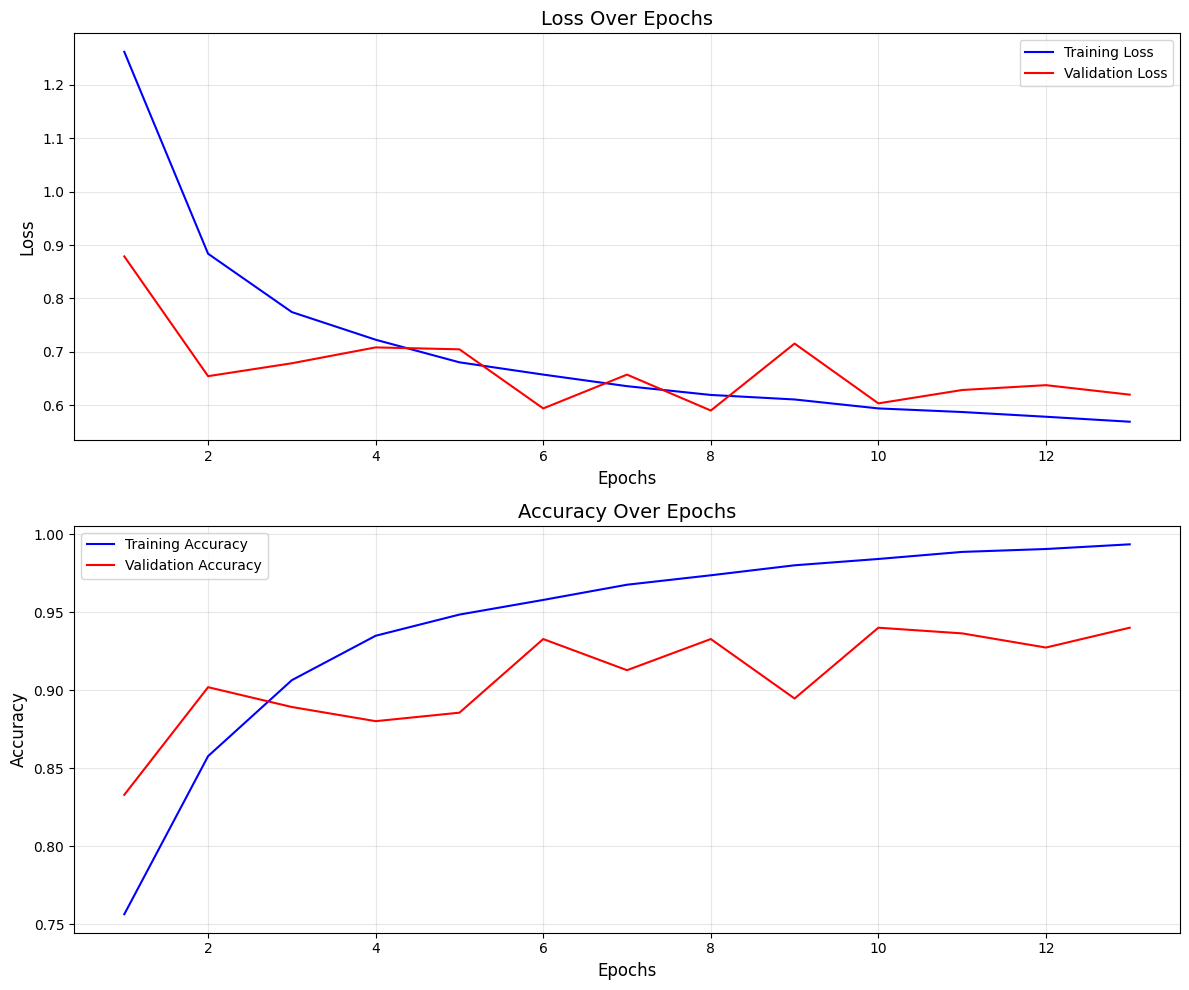

In [9]:
# Initialize training module
train_module = TrainModule(config, model, train_loader, val_loader)

# Train the model
print("\nStarting training...")
model = train_module.train()

# Plot training metrics
train_module.plot_metrics()

##**7. Model Evaluation**
Let's define our enhanced evaluation functions:

In [11]:
class EvaluationModule:
    def __init__(self, config, model, test_loader, class_names):
        self.config = config
        self.model = model
        self.test_loader = test_loader
        self.class_names = class_names

    def evaluate(self):
        """Evaluate the model on the test set"""
        # Set model to evaluation mode
        self.model.eval()

        # Lists to store test labels and predictions
        true_labels = []
        predictions = []
        all_probabilities = []

        # Evaluate without gradient tracking
        with torch.no_grad():
            for images, labels in tqdm(self.test_loader, desc="Testing"):
                # Move images to device
                images = images.to(self.config.DEVICE)

                # Forward pass
                outputs = self.model(images)

                # Get predictions and probabilities
                probabilities = F.softmax(outputs, dim=1)
                _, batch_preds = torch.max(outputs, 1)

                # Store labels, predictions, and probabilities
                true_labels.extend(labels.cpu().numpy())
                predictions.extend(batch_preds.cpu().numpy())
                all_probabilities.extend(probabilities.cpu().numpy())

        # Compute confusion matrix
        self.cm = confusion_matrix(true_labels, predictions)

        # Generate classification report
        self.report = classification_report(
            true_labels,
            predictions,
            target_names=self.class_names,
            output_dict=True
        )

        # Print classification report
        print("Test Classification Report:")
        print(classification_report(true_labels, predictions, target_names=self.class_names))

        # Calculate overall accuracy
        self.accuracy = (np.array(true_labels) == np.array(predictions)).mean()
        print(f"Overall Test Accuracy: {self.accuracy:.4f}")

        # Store results for later use
        self.true_labels = true_labels
        self.predictions = predictions
        self.probabilities = all_probabilities

        return self.accuracy, self.cm, self.report

    def plot_confusion_matrix(self, normalize=False, title='Confusion Matrix', cmap=plt.cm.Blues):
        """Plot the confusion matrix with abbreviated class names"""
        plt.figure(figsize=(10, 8))
        plt.imshow(self.cm, interpolation='nearest', cmap=cmap)
        plt.title(title, fontsize=14)
        plt.colorbar()

        # Define abbreviations for each class
        class_abbreviations = {
            'Benign keratosis-like lesions': 'bkl',
            'Melanocytic nevi': 'nv',
            'Dermatofibroma': 'df',
            'Melanoma': 'mel',
            'Vascular lesions': 'vasc',
            'Basal cell carcinoma': 'bcc',
            'Actinic keratoses': 'akiec'
        }

        # Create abbreviated label list
        abbreviated_labels = [class_abbreviations.get(name, name) for name in self.class_names]

        # Set tick marks
        tick_marks = np.arange(len(self.class_names))
        plt.xticks(tick_marks, abbreviated_labels, rotation=0, fontsize=10)
        plt.yticks(tick_marks, abbreviated_labels, fontsize=10)

        # Normalize if requested
        if normalize:
            cm = self.cm.astype('float') / self.cm.sum(axis=1)[:, np.newaxis]
            fmt = '.2f'
        else:
            cm = self.cm
            fmt = 'd'

        # Add text annotations
        thresh = cm.max() / 2.
        for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
            plt.text(j, i, format(cm[i, j], fmt),
                    horizontalalignment="center",
                    fontsize=12,
                    fontweight='bold',
                    color="white" if cm[i, j] > thresh else "black")

        plt.tight_layout()
        plt.ylabel('True Label', fontsize=12)
        plt.xlabel('Predicted Label', fontsize=12)
        plt.savefig(os.path.join(self.config.OUTPUT_DIR, 'confusion_matrix.png'), dpi=300)

        # Add a legend that maps abbreviations to full names
        plt.figtext(0.5, 0.01,
                  '\n'.join([f"{abbr}: {full}" for abbr, full in class_abbreviations.items()]),
                  ha="center", fontsize=8, bbox={"facecolor":"white", "alpha":0.5, "pad":5})

        plt.subplots_adjust(bottom=0.2)  # Make room for the legend
        plt.show()

    # def plot_confusion_matrix(self, normalize=False, title='Confusion Matrix', cmap=plt.cm.Blues):
    #     """Plot the confusion matrix with improved formatting"""
    #     # Create larger figure with better proportions
    #     plt.figure(figsize=(12, 10))

    #     # Plot the confusion matrix
    #     plt.imshow(self.cm, interpolation='nearest', cmap=cmap)
    #     plt.title(title, fontsize=16, pad=10)
    #     plt.colorbar()

    #     # Format class names for consistency (shorter labels if needed)
    #     formatted_class_names = [name.replace('-', '\n') for name in self.class_names]

    #     # Set tick marks
    #     tick_marks = np.arange(len(formatted_class_names))

    #     # Set x-axis labels with HORIZONTAL orientation and better spacing
    #     plt.xticks(tick_marks, formatted_class_names, rotation=0, fontsize=10, ha='center')
    #     plt.yticks(tick_marks, formatted_class_names, fontsize=10, va='center')

    #     # Normalize if requested
    #     if normalize:
    #         cm = self.cm.astype('float') / self.cm.sum(axis=1)[:, np.newaxis]
    #         fmt = '.2f'
    #     else:
    #         cm = self.cm
    #         fmt = 'd'

    #     # Add text annotations with improved visibility
    #     thresh = cm.max() / 2.
    #     for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    #         # Make text annotations larger and bolder for better visibility
    #         plt.text(j, i, format(cm[i, j], fmt),
    #                 horizontalalignment="center",
    #                 verticalalignment="center",
    #                 fontsize=12,
    #                 fontweight='bold',
    #                 color="white" if cm[i, j] > thresh else "black")

    #     # Add more space at the bottom for x-axis labels
    #     plt.tight_layout(rect=[0, 0.03, 1, 0.95])

    #     # Improve axis labels with clearer font
    #     plt.ylabel('True Label', fontsize=14, labelpad=10)
    #     plt.xlabel('Predicted Label', fontsize=14, labelpad=10)

    #     # Save with better DPI for clarity
    #     plt.savefig(os.path.join(self.config.OUTPUT_DIR, 'confusion_matrix.png'), dpi=300, bbox_inches='tight')
    #     plt.show()

    def plot_error_rates(self):
        """Plot error rates by class with improved formatting"""
        # Calculate error rates for each class
        error_rates = 1 - np.diag(self.cm) / np.sum(self.cm, axis=1)

        # Create a better proportioned figure
        plt.figure(figsize=(12, 6))

        # Create more visually distinct bars
        bars = plt.bar(
            np.arange(len(self.class_names)),
            error_rates,
            width=0.6,  # Slightly narrower bars
            color='#3274A1',  # Professional blue color
            edgecolor='black',  # Add border for clarity
            linewidth=0.5
        )

        # Create shorter display names for better formatting
        display_names = []
        for name in self.class_names:
            # Abbreviate names for cleaner display
            parts = name.split()
            if len(parts) > 2:
                display_names.append(f"{parts[0]}\n{' '.join(parts[1:])}")
            else:
                display_names.append(name)

        # Set axis labels and title with improved styling
        plt.xlabel('Class', fontsize=12, labelpad=10)
        plt.ylabel('Error Rate', fontsize=12, labelpad=10)
        plt.title('Error Rates by Class', fontsize=14, pad=10)

        # Set x-axis ticks directly aligned with bars
        plt.xticks(
            np.arange(len(self.class_names)),
            display_names,
            rotation=0,  # Horizontal text
            fontsize=10,
            ha='center'  # Center align text with bars
        )

        # Add value labels above bars
        for bar in bars:
            height = bar.get_height()
            plt.text(
                bar.get_x() + bar.get_width()/2.,
                height + 0.01,
                f'{height:.2f}',
                ha='center',
                va='bottom',
                fontsize=9
            )

        # Improve grid for better readability - only horizontal lines
        plt.grid(axis='y', linestyle='--', alpha=0.7)

        # Set y-axis limit slightly higher to fit value labels
        plt.ylim(0, max(error_rates) * 1.15)

        plt.tight_layout()
        plt.savefig(os.path.join(self.config.OUTPUT_DIR, 'error_rates.png'), dpi=300, bbox_inches='tight')
        plt.show()

    def visualize_class_performance(self):
        """Visualize precision, recall, and f1-score for each class with improved formatting"""
        # Extract metrics from classification report
        classes = list(self.report.keys())[:-3]  # Exclude 'accuracy', 'macro avg', 'weighted avg'
        precision = [self.report[c]['precision'] for c in classes]
        recall = [self.report[c]['recall'] for c in classes]
        f1_score = [self.report[c]['f1-score'] for c in classes]

        # Create more consistent display names
        display_names = []
        for name in self.class_names:
            parts = name.split()
            if len(parts) > 2:
                display_names.append(f"{parts[0]}\n{' '.join(parts[1:])}")
            else:
                display_names.append(name)

        # Set up the figure with better proportions
        fig, ax = plt.subplots(figsize=(14, 7))

        # Set width of bars
        bar_width = 0.25
        r1 = np.arange(len(classes))
        r2 = [x + bar_width for x in r1]
        r3 = [x + bar_width for x in r2]

        # Create bars with distinct colors and borders
        ax.bar(r1, precision, width=bar_width, label='Precision', color='#3274A1', edgecolor='black', linewidth=0.5)
        ax.bar(r2, recall, width=bar_width, label='Recall', color='#E1812C', edgecolor='black', linewidth=0.5)
        ax.bar(r3, f1_score, width=bar_width, label='F1-Score', color='#3A923A', edgecolor='black', linewidth=0.5)

        # Add labels and title with improved formatting
        ax.set_xlabel('Class', fontsize=12, labelpad=10)
        ax.set_ylabel('Score', fontsize=12, labelpad=10)
        ax.set_title('Performance Metrics by Class', fontsize=16, pad=15)

        # Position xticks properly in the middle of the three bars
        ax.set_xticks([r + bar_width for r in range(len(classes))])
        ax.set_xticklabels(display_names, rotation=0, fontsize=10, ha='center')

        # Add horizontal grid lines for better readability
        ax.grid(axis='y', linestyle='--', alpha=0.7)

        # Set y-axis limits for consistency
        ax.set_ylim(0, 1.05)

        # Add a thin horizontal line at y=0.5 for reference
        ax.axhline(y=0.5, color='gray', linestyle='-', alpha=0.3)

        # Enhance legend with better positioning and formatting
        ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.15),
                  ncol=3, frameon=True, fontsize=10)

        # Add value labels on bars
        for i, bars in enumerate([r1, r2, r3]):
            values = [precision, recall, f1_score][i]
            for j, v in enumerate(values):
                ax.text(bars[j], v + 0.02, f'{v:.2f}',
                      ha='center', va='bottom', fontsize=8)

        plt.tight_layout(rect=[0, 0.05, 1, 0.95])  # Adjust for legend at bottom
        plt.savefig(os.path.join(self.config.OUTPUT_DIR, 'class_performance.png'), dpi=300, bbox_inches='tight')
        plt.show()

    def plot_roc_curves(self):
        """Plot ROC curves for each class"""
        from sklearn.metrics import roc_curve, auc

        # Convert lists to numpy arrays
        y_true = np.array(self.true_labels)
        y_score = np.array(self.probabilities)

        # Compute ROC curve and ROC area for each class
        fpr = dict()
        tpr = dict()
        roc_auc = dict()

        plt.figure(figsize=(12, 10))

        for i in range(len(self.class_names)):
            # Binarize the labels for one-vs-rest approach
            y_true_bin = (y_true == i).astype(int)
            y_score_i = y_score[:, i]

            fpr[i], tpr[i], _ = roc_curve(y_true_bin, y_score_i)
            roc_auc[i] = auc(fpr[i], tpr[i])

            # Plot ROC curve for this class
            plt.plot(fpr[i], tpr[i], lw=2,
                    label=f'{self.class_names[i]} (AUC = {roc_auc[i]:.2f})')

        # Plot random chance line
        plt.plot([0, 1], [0, 1], 'k--', lw=2)

        plt.xlim([0.0, 1.0])
        plt.ylim([0.0, 1.05])
        plt.xlabel('False Positive Rate', fontsize=12)
        plt.ylabel('True Positive Rate', fontsize=12)
        plt.title('Receiver Operating Characteristic (ROC) Curves', fontsize=14)
        plt.legend(loc="lower right", fontsize=10)
        plt.grid(alpha=0.3)

        plt.tight_layout()
        plt.savefig(os.path.join(self.config.OUTPUT_DIR, 'roc_curves.png'), dpi=300, bbox_inches='tight')
        plt.show()

**Let's evaluate our model:**

Testing: 100%|██████████| 69/69 [00:03<00:00, 17.31it/s]


Test Classification Report:
                               precision    recall  f1-score   support

Benign keratosis-like lesions       0.91      0.53      0.67        19
             Melanocytic nevi       0.95      0.95      0.95        20
               Dermatofibroma       0.77      0.88      0.82        50
                     Melanoma       0.67      0.67      0.67         3
             Vascular lesions       0.98      0.96      0.97       435
         Basal cell carcinoma       0.55      0.78      0.64        23
            Actinic keratoses       1.00      1.00      1.00         2

                     accuracy                           0.93       552
                    macro avg       0.83      0.82      0.82       552
                 weighted avg       0.94      0.93      0.93       552

Overall Test Accuracy: 0.9293


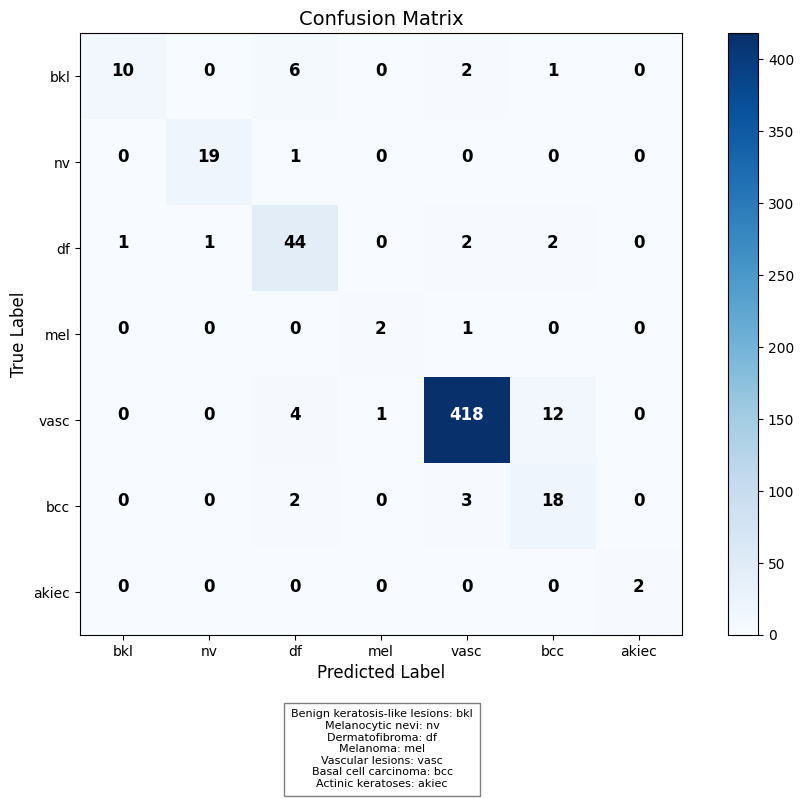

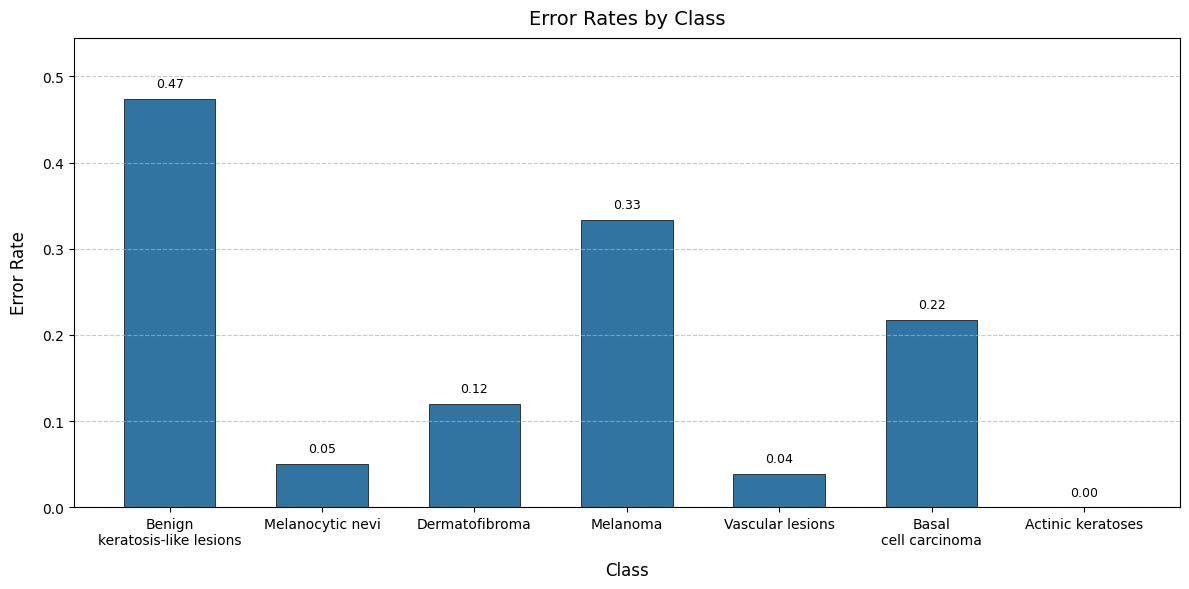

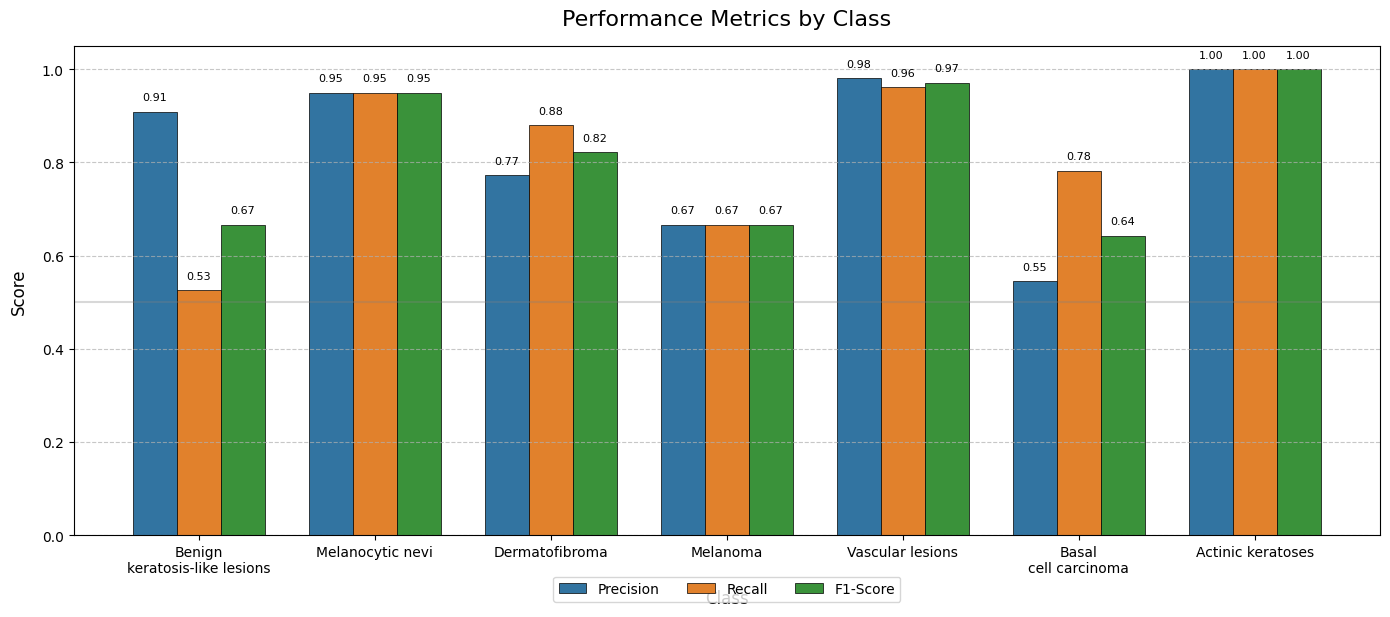

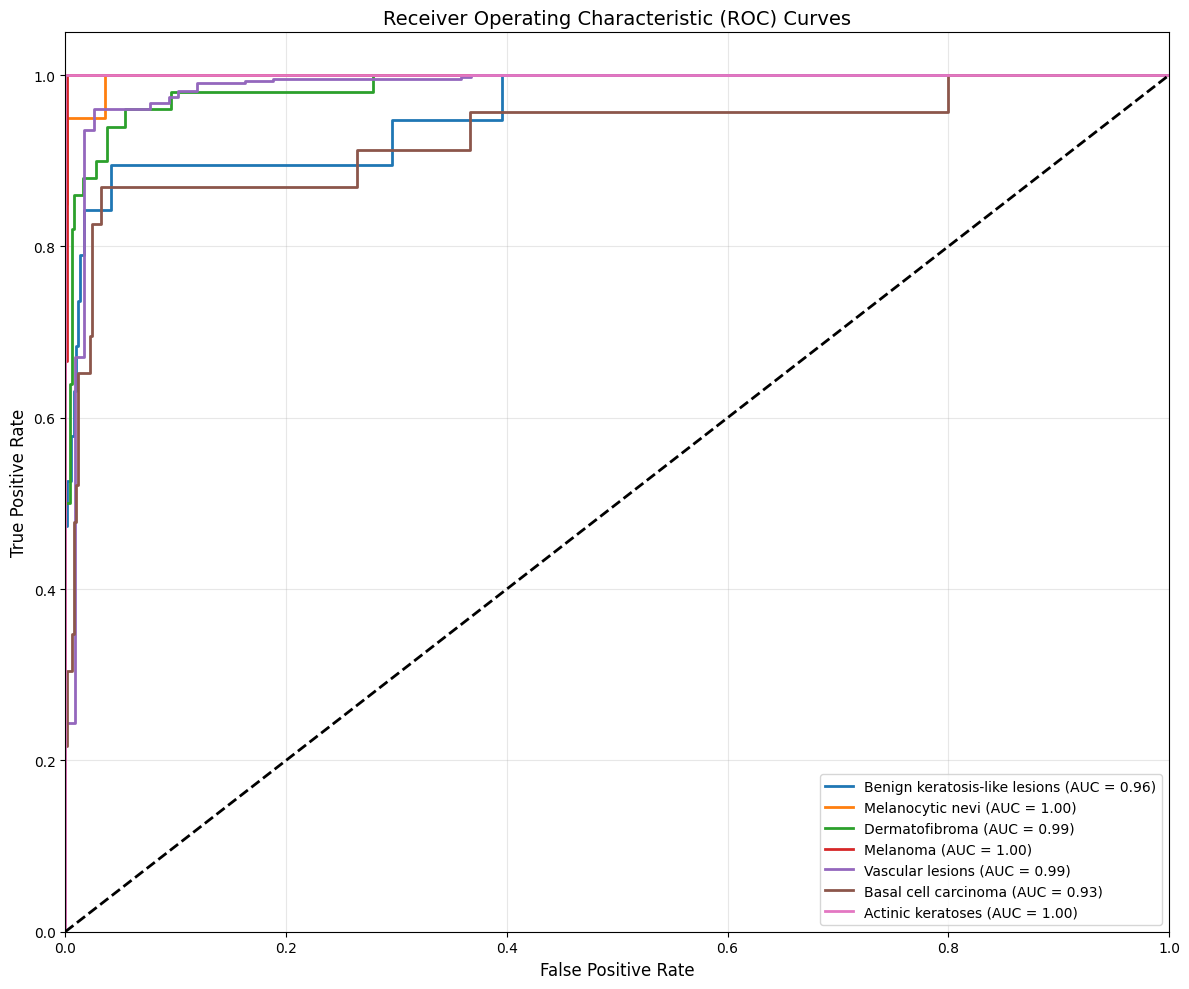

In [12]:
# Initialize evaluation module
eval_module = EvaluationModule(config, model, test_loader, class_names)

# Evaluate the model
accuracy, confusion_mat, report = eval_module.evaluate()

# Visualize results
eval_module.plot_confusion_matrix()
eval_module.plot_error_rates()
eval_module.visualize_class_performance()
eval_module.plot_roc_curves()

##**8. Model Saving and Loading**
Let's save our fully trained model:

In [14]:
!pip install onnx
!pip install onnx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 101.4 MB/s eta 0:00:00


In [15]:

import os
import torch
import torch.nn.functional as F
from PIL import Image
import torchvision.transforms as transforms


# Save the complete model (architecture + parameters)
torch.save(model, os.path.join(config.OUTPUT_DIR, 'EfficientNetV2Large_ham10000.pth'))
print("Complete model saved!")

# Save model in ONNX format for deployment
dummy_input = torch.randn(1, 3, config.IMG_SIZE, config.IMG_SIZE, device=config.DEVICE)
input_names = ["input"]
output_names = ["output"]

torch.onnx.export(
    model,
    dummy_input,
    os.path.join(config.OUTPUT_DIR, 'EfficientNetV2Large_ham10000.onnx'),
    input_names=input_names,
    output_names=output_names,
    export_params=True,
    opset_version=12,
    do_constant_folding=True,
    verbose=False
)
print("ONNX model saved for deployment!")

# Example of how to load the model for inference
def load_model_for_inference(model_path, device):
    model = torch.load(model_path, map_location=device)
    model.eval()  # Set to evaluation mode
    return model

# Example: how to use the model for predictions
def predict_single_image(model, image_path, transform, device, class_names):
    # Load and preprocess the image
    image = Image.open(image_path).convert('RGB')
    image = transform(image).unsqueeze(0).to(device)

    # Get prediction
    with torch.no_grad():
        outputs = model(image)
        probabilities = F.softmax(outputs, dim=1)
        confidence, prediction = torch.max(probabilities, 1)

    return {
        'class_id': prediction.item(),
        'class_name': class_names[prediction.item()],
        'confidence': confidence.item()
    }

Complete model saved!
ONNX model saved for deployment!


In [18]:
# Install zip if not already available
!apt-get install -y zip unzip

# Navigate to the parent directory
!cd /content

# Create a ZIP archive of your output folder
!zip -r EfficientNetV2Large_Output.zip output

# Download the zipped folder
from google.colab import files
files.download('/content/EfficientNetV2Large_Output.zip')

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
zip is already the newest version (3.0-12build2).
unzip is already the newest version (6.0-26ubuntu3.2).
0 upgraded, 0 newly installed, 0 to remove and 29 not upgraded.
  adding: output/ (stored 0%)
  adding: output/EfficientNetV2Large_ham10000.onnx (deflated 10%)
  adding: output/error_rates.png (deflated 29%)
  adding: output/class_performance.png (deflated 28%)
  adding: output/logs/ (stored 0%)
  adding: output/logs/training_log.csv (deflated 53%)
  adding: output/EfficientNetV2Large_ham10000.pth (deflated 10%)
  adding: output/checkpoints/ (stored 0%)
  adding: output/checkpoints/best_model.pth (deflated 9%)
  adding: output/checkpoints/checkpoint_epoch_10.pth (deflated 9%)
  adding: output/checkpoints/checkpoint_epoch_5.pth (deflated 9%)
  adding: output/confusion_matrix.png (deflated 29%)
  adding: output/roc_curves.png (deflated 24%)
  adding: output/training_metrics.png (deflated 1

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Summary: Skin Cancer Classification with EfficientNetV2
Key Components:

Data Preparation:

HAM10000 dataset with 7 skin lesion classes
Handling of duplicate lesions to prevent data leakage
Stratified train/validation/test splits
Class balancing through oversampling
Enhanced data augmentation for medical images
Implementation of Mixup augmentation technique


Model Architecture:

EfficientNetV2-S with transfer learning
Fine-tuning approach for all layers
Dropout for regularization
Modified classifier for 7-class classification


Training Approach:

AdamW optimizer with weight decay
One-Cycle learning rate scheduler with warmup
CrossEntropyLoss with label smoothing
Early stopping to prevent overfitting
Automatic Mixed Precision (AMP) for faster training
Gradient accumulation for larger effective batch sizes
Gradient clipping to prevent exploding gradients


Evaluation:

Confusion matrix analysis
Class-specific metrics (precision, recall, F1-score)
Error rate analysis by class
ROC curve analysis for each class
Model export to ONNX for deployment



Key Improvements:

Model: EfficientNetV2 is more efficient, accurate, and faster than MobileNetV3 for this task
Training: Added early stopping, mixed precision, and gradient accumulation
Augmentation: Added Mixup augmentation technique for better generalization
Regularization: Added label smoothing and dropout for improved generalization
Evaluation: Enhanced with ROC curve analysis and ONNX export
Learning Rate: Implemented OneCycleLR scheduler with warmup for faster convergence
Optimization: Used AdamW optimizer with gradient clipping for better stability